# APMA 80 — Aprendizagem de Máquina
## Prática das Aulas 07 e 08

**Aula 07** — Regressão Linear e Avaliação (MSE, RMSE, R²)
**Aula 08** — Regressão Logística: Primeiro Classificador (sigmoide, fronteira de decisão, threshold)

> Este notebook segue exatamente o fluxo apresentado em aula: `carregar dados → separar X e y → dividir treino/teste → treinar (.fit) → prever (.predict) → avaliar`.
> Rode as células em ordem, de cima para baixo.


In [1]:
# Bibliotecas usadas em todo o notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# deixa os gráficos com um tamanho mais confortável
plt.rcParams["figure.figsize"] = (7, 4.5)


---
# 🏠 Aula 07 — Regressão Linear e Avaliação

**Problema:** prever o **preço de um imóvel** a partir do seu **tamanho (m²)**.

Vamos seguir o fluxo completo:
1. Carregar (gerar) os dados
2. Explorar o DataFrame
3. Separar X (tamanho) e y (preço)
4. Dividir em treino e teste
5. Treinar um `LinearRegression`
6. Prever e interpretar os coeficientes
7. Avaliar com MSE, RMSE e R²


## 1. Carregando os dados

Como ainda não temos um CSV real de imóveis, vamos **gerar um dataset sintético** com uma relação aproximadamente linear entre tamanho e preço — a mesma ideia usada em aula, mas com controle total sobre o ruído.

In [2]:
np.random.seed(42)

tamanho = np.random.uniform(30, 200, 150)                      # m²
preco = 3000 * tamanho + np.random.normal(0, 20000, 150) + 50000  # preço com ruído (R$)

df = pd.DataFrame({"tamanho_m2": tamanho, "preco": preco})
df.to_csv("imoveis.csv", index=False)

df.head()


,tamanho_m2,preco
0,93.671820,327168.241317
1,191.621432,630895.243116
2,154.438970,512622.674930
3,131.771942,421942.266188
4,56.523169,242425.962916


## 2. Explorando o DataFrame

O primeiro olhar obrigatório antes de qualquer modelagem: `.head()`, `.shape` e `.info()`.

In [3]:
print("Formato (linhas, colunas):", df.shape)
df.info()


Formato (linhas, colunas): (150, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   tamanho_m2  150 non-null    float64
 1   preco       150 non-null    float64
dtypes: float64(2)
memory usage: 2.5 KB


In [4]:
df.describe()


,tamanho_m2,preco
count,150.000000,150.000000
mean,110.390813,382109.597732
std,50.410232,153656.626884
min,30.938760,101428.816336
25%,66.512819,246433.360350
50%,106.178911,380061.385084
75%,157.442513,516628.294479
max,197.770779,678463.137119


### Visualizando a relação entre tamanho e preço

Antes de treinar qualquer modelo, sempre vale olhar o gráfico de dispersão — a relação parece linear?

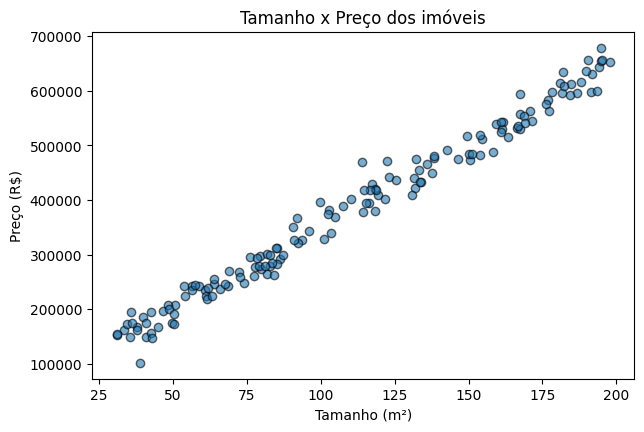

In [5]:
plt.scatter(df["tamanho_m2"], df["preco"], alpha=0.6, edgecolor="k")
plt.xlabel("Tamanho (m²)")
plt.ylabel("Preço (R$)")
plt.title("Tamanho x Preço dos imóveis")
plt.show()


## 3. Separando X (features) e y (target)

- **x** = variável independente → `tamanho_m2`
- **y** = variável dependente → `preco`

Repare que `X` precisa ser um DataFrame (por isso os **dois colchetes**), e `y` pode ser uma Series (**um colchete**).


In [6]:
X = df[["tamanho_m2"]]   # 2 colchetes -> DataFrame
y = df["preco"]           # 1 colchete -> Series


## 4. Dividindo em treino e teste

- `test_size=0.2` → reserva 20% dos dados para teste e 80% para treino.
- `random_state=42` → garante que a divisão seja sempre a mesma (reprodutibilidade).

**Por que dividir?** Se treinarmos e avaliarmos com os mesmos dados, o modelo pode "decorar" os exemplos vistos e parecer ótimo sem ter aprendido de verdade. O conjunto de teste simula dados novos, nunca vistos.


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Treino:", X_train.shape[0], "exemplos")
print("Teste: ", X_test.shape[0], "exemplos")


Treino: 120 exemplos
Teste:  30 exemplos


## 5. Treinando o modelo

- `LinearRegression()` cria o modelo — ainda "vazio", como uma folha em branco.
- `.fit()` executa o método dos mínimos quadrados e encontra os melhores valores de **a** (coeficiente) e **b** (intercepto).


In [22]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Coeficiente (a): {model.coef_[0]:.2f}")
print(f"Intercepto (b): {model.intercept_:.2f}")

# y = 3033.70 * x + 48_289.40

Coeficiente (a): 3033.70
Intercepto (b): 48289.40


### Interpretando os coeficientes

> "A cada m² a mais no imóvel, o preço sobe aproximadamente **R$ {a:.0f}**."

Isso é exatamente o que o coeficiente `a` representa: o quanto `y` muda para cada unidade de `x`.


## 6. Prevendo e visualizando a reta ajustada

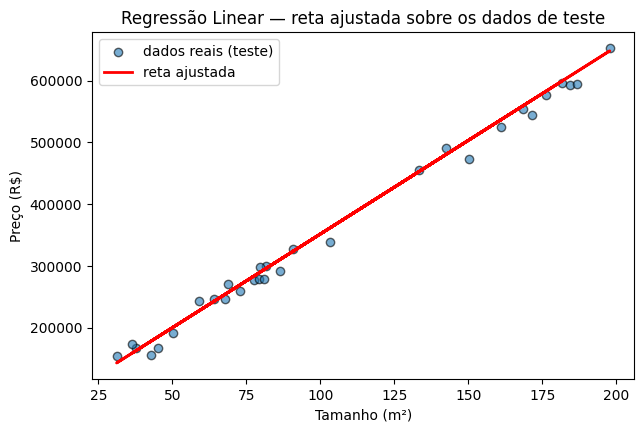

In [9]:
y_pred = model.predict(X_test)

plt.scatter(X_test, y_test, alpha=0.6, edgecolor="k", label="dados reais (teste)")
plt.plot(X_test, y_pred, color="red", linewidth=2, label="reta ajustada")
plt.xlabel("Tamanho (m²)")
plt.ylabel("Preço (R$)")
plt.title("Regressão Linear — reta ajustada sobre os dados de teste")
plt.legend()
plt.show()


## 7. Avaliando o modelo

- **MSE / RMSE** → tamanho do erro, na unidade do problema (R$).
- **R²** → quanto da variação do preço o modelo consegue explicar.

Regra de ouro: **sempre avalie no conjunto de teste**, nunca no de treino.


In [10]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}  (erro típico em R$)")
print(f"R²:   {r2:.3f}")


MSE:  189,929,093.38
RMSE: 13,781.48  (erro típico em R$)
R²:   0.992


**Interpretação rápida (regra de bolso da disciplina):**
- R² > 0,7 → modelo forte
- R² entre 0,4 e 0,7 → modelo moderado
- R² < 0,4 → modelo fraco

Compare o R² obtido acima com essa régua e escreva sua conclusão numa célula de texto, se quiser.


### 💡 Exercício rápido
Tente prever o preço de um imóvel de **110 m²** usando o modelo treinado.


In [11]:
novo_imovel = pd.DataFrame({"tamanho_m2": [110]})
preco_previsto = model.predict(novo_imovel)
print(f"Preço previsto para 110 m²: R$ {preco_previsto[0]:,.2f}")


Preço previsto para 110 m²: R$ 381,996.31


---
# 🎓 Aula 08 — Regressão Logística: Primeiro Classificador

**Problema:** prever se um aluno **foi aprovado ou não** a partir das **horas de estudo**.

Fluxo:
1. Gerar o dataset
2. Explorar e visualizar
3. Separar X, y e dividir treino/teste
4. Treinar um `LogisticRegression`
5. Prever classes e probabilidades (`predict` x `predict_proba`)
6. Visualizar a curva sigmoide ajustada
7. Testar diferentes thresholds
8. Avaliar com `.score()`


## 1. Gerando o dataset

A própria função sigmoide gera as probabilidades de aprovação — é o mesmo padrão matemático que o modelo vai tentar redescobrir a partir dos dados.

In [12]:
np.random.seed(42)

horas = np.random.uniform(0, 10, 150)
prob_real = 1 / (1 + np.exp(-(horas - 5)))     # sigmoide "verdadeira"
aprovado = np.random.binomial(1, prob_real)     # sorteia 0/1 com base na probabilidade

df2 = pd.DataFrame({"horas_estudo": horas, "aprovado": aprovado})
df2.head()


,horas_estudo,aprovado
0,3.745401,1
1,9.507143,1
2,7.319939,1
3,5.986585,1
4,1.560186,1


## 2. Explorando o dataset

In [13]:
print(df2["aprovado"].value_counts())
print()
print(df2["aprovado"].value_counts(normalize=True))


aprovado
0    76
1    74
Name: count, dtype: int64

aprovado
0    0.506667
1    0.493333
Name: proportion, dtype: float64


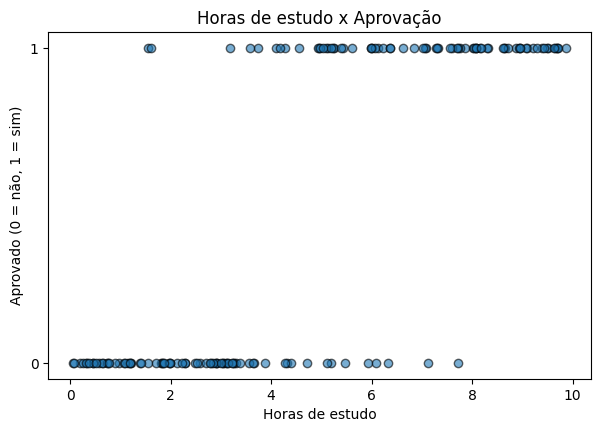

In [14]:
plt.scatter(df2["horas_estudo"], df2["aprovado"], alpha=0.6, edgecolor="k")
plt.xlabel("Horas de estudo")
plt.ylabel("Aprovado (0 = não, 1 = sim)")
plt.title("Horas de estudo x Aprovação")
plt.yticks([0, 1])
plt.show()


## 3. Separando X, y e dividindo treino/teste

Mesmo padrão da Aula 07: separar X e y, depois dividir em treino e teste antes de qualquer treinamento.


In [15]:
X2 = df2[["horas_estudo"]]
y2 = df2["aprovado"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

print("Treino:", X2_train.shape[0], "exemplos")
print("Teste: ", X2_test.shape[0], "exemplos")


Treino: 120 exemplos
Teste:  30 exemplos


## 4. Treinando o modelo

`LogisticRegression()` cria o modelo; `.fit()` encontra os melhores coeficientes usando **log-loss** como função de custo (em vez do MSE usado na regressão linear).


In [16]:
from sklearn.linear_model import LogisticRegression

model_log = LogisticRegression()
model_log.fit(X2_train, y2_train)

print(f"Coeficiente: {model_log.coef_[0][0]:.3f}")
print(f"Intercepto:  {model_log.intercept_[0]:.3f}")


Coeficiente: 0.978
Intercepto:  -4.412


## 5. Prevendo classes e probabilidades

- `.predict()` retorna diretamente **0 ou 1**.
- `.predict_proba()` retorna as **probabilidades** de cada classe (colunas: classe 0, classe 1 — sempre somam 1).


In [17]:
y2_pred = model_log.predict(X2_test)

probas = model_log.predict_proba(X2_test)
print("Primeiras previsões de classe: ", y2_pred[:5])
print("Primeiras probabilidades [P(0), P(1)]:")
print(probas[:5].round(3))


Primeiras previsões de classe:  [1 0 1 0 1]
Primeiras probabilidades [P(0), P(1)]:
[[0.028 0.972]
 [0.547 0.453]
 [0.013 0.987]
 [0.713 0.287]
 [0.042 0.958]]


## 6. Visualizando a curva sigmoide ajustada

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


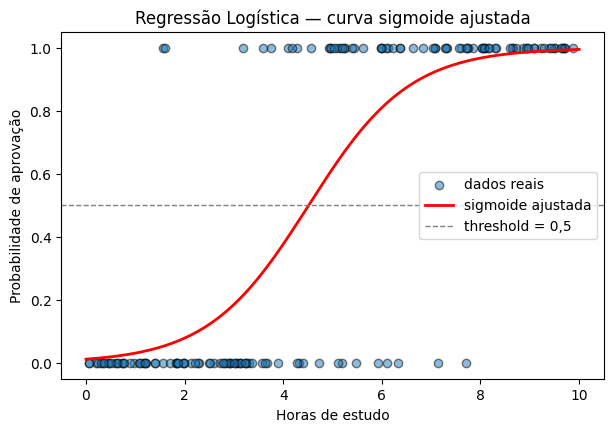

In [18]:
horas_range = np.linspace(0, 10, 200).reshape(-1, 1)
probs_range = model_log.predict_proba(horas_range)[:, 1]

plt.scatter(df2["horas_estudo"], df2["aprovado"], alpha=0.5, edgecolor="k", label="dados reais")
plt.plot(horas_range, probs_range, color="red", linewidth=2, label="sigmoide ajustada")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="threshold = 0,5")
plt.xlabel("Horas de estudo")
plt.ylabel("Probabilidade de aprovação")
plt.title("Regressão Logística — curva sigmoide ajustada")
plt.legend()
plt.show()


## 7. Testando diferentes thresholds

O threshold padrão é 0,5, mas pode ser ajustado conforme o problema. Vamos ver o que acontece com threshold = 0,3 (mais sensível) e threshold = 0,7 (mais rigoroso).


In [19]:
for threshold in [0.3, 0.5, 0.7]:
    y_pred_custom = (model_log.predict_proba(X2_test)[:, 1] >= threshold).astype(int)
    aprovados_previstos = y_pred_custom.sum()
    print(f"threshold = {threshold} -> {aprovados_previstos} de {len(y_pred_custom)} classificados como aprovados")


threshold = 0.3 -> 12 de 30 classificados como aprovados
threshold = 0.5 -> 11 de 30 classificados como aprovados
threshold = 0.7 -> 11 de 30 classificados como aprovados


## 8. Avaliação simples

⚠️ **Atenção:** `.score()` só mostra a **acurácia** — na próxima aula (Aula 09) veremos por que isso não é suficiente sozinho, especialmente em datasets desbalanceados.


In [20]:
acuracia = model_log.score(X2_test, y2_test)
print(f"Acurácia no conjunto de teste: {acuracia:.3f}")


Acurácia no conjunto de teste: 0.933


### 💡 Exercício rápido
Um aluno estudou **4,5 horas**. Qual a probabilidade prevista de aprovação, e qual seria a classe final com threshold = 0,5?


In [21]:
novo_aluno = pd.DataFrame({"horas_estudo": [4.5]})
proba_novo = model_log.predict_proba(novo_aluno)[0, 1]
classe_novo = model_log.predict(novo_aluno)[0]

print(f"P(aprovado) = {proba_novo:.3f}")
print(f"Classe prevista (threshold 0,5): {'aprovado' if classe_novo == 1 else 'não aprovado'}")


P(aprovado) = 0.497
Classe prevista (threshold 0,5): não aprovado


---

## 9. Aula 09 — Métricas de Avaliação para Classificação

Nesta seção, vamos aprofundar a avaliação do modelo de Regressão Logística, calculando métricas como Precisão, Recall e F1-Score, além de visualizar a Matriz de Confusão.

### Matriz de Confusão

In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y2_test, y2_pred)
print("Matriz de Confusão:")
print(cm)

Matriz de Confusão:
[[18  1]
 [ 1 10]]


### Visualizando a Matriz de Confusão

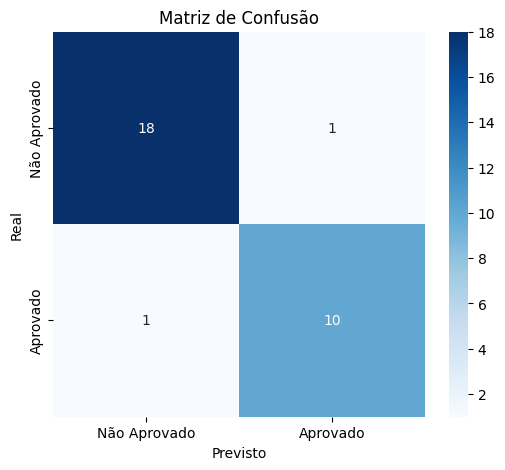

In [25]:
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não Aprovado', 'Aprovado'],
            yticklabels=['Não Aprovado', 'Aprovado'])
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()

### Calculando Precisão, Recall e F1-Score

In [23]:
from sklearn.metrics import classification_report

print(classification_report(y2_test, y2_pred))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95        19
           1       0.91      0.91      0.91        11

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



---
## Recapitulando

| | Aula 07 — Regressão Linear | Aula 08 — Regressão Logística |
|---|---|---|
| Saída | número contínuo | probabilidade (0 a 1) |
| Função | reta (y = a·x + b) | sigmoide (σ(z)) |
| Custo minimizado | MSE | log-loss |
| Avaliação | MSE, RMSE, R² | acurácia (`.score()`) — **insuficiente sozinha!** |
